In [3]:
!pip install kagglehub[pandas-datasets]

In [1]:
import geopandas as gpd
import os
import kagglehub

In [8]:

# Download the latest version of the dataset
path = kagglehub.dataset_download("alexisbcook/geospatial-learn-course-data")

print("Dataset downloaded to:", path)

# Construct the path to the DEC lands shapefile
shp_path = os.path.join(path, "DEC_lands", "DEC_lands", "DEC_lands.shp")

# Load the shapefile using geopandas
full_data = gpd.read_file(shp_path)

# View the first five rows
full_data.head()

100%|██████████| 233M/233M [00:11<00:00, 21.2MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/alexisbcook/geospatial-learn-course-data/versions/2


,OBJECTID,CATEGORY,UNIT,FACILITY,CLASS,UMP,DESCRIPTIO,REGION,COUNTY,URL,SOURCE,UPDATE_,OFFICE,ACRES,LANDS_UID,GREENCERT,SHAPE_AREA,SHAPE_LEN,geometry
0,1,FOR PRES DET PAR,CFP,HANCOCK FP DETACHED PARCEL,WILD FOREST,None,DELAWARE COUNTY DETACHED PARCEL,4,DELAWARE,http://www.dec.ny.gov/,DELAWARE RPP,5/12,STAMFORD,738.620192,103,N,2.990365e+06,7927.662385,"POLYGON ((486093.245 4635308.586, 486787.235 4..."
1,2,FOR PRES DET PAR,CFP,HANCOCK FP DETACHED PARCEL,WILD FOREST,None,DELAWARE COUNTY DETACHED PARCEL,4,DELAWARE,http://www.dec.ny.gov/,DELAWARE RPP,5/12,STAMFORD,282.553140,1218,N,1.143940e+06,4776.375600,"POLYGON ((491931.514 4637416.256, 491305.424 4..."
2,3,FOR PRES DET PAR,CFP,HANCOCK FP DETACHED PARCEL,WILD FOREST,None,DELAWARE COUNTY DETACHED PARCEL,4,DELAWARE,http://www.dec.ny.gov/,DELAWARE RPP,5/12,STAMFORD,234.291262,1780,N,9.485476e+05,5783.070364,"POLYGON ((486000.287 4635834.453, 485007.55 46..."
3,4,FOR PRES DET PAR,CFP,GREENE COUNTY FP DETACHED PARCEL,WILD FOREST,None,None,4,GREENE,http://www.dec.ny.gov/,GREENE RPP,5/12,STAMFORD,450.106464,2060,N,1.822293e+06,7021.644833,"POLYGON ((541716.775 4675243.268, 541217.58 46..."
4,6,FOREST PRESERVE,AFP,SARANAC LAKES WILD FOREST,WILD FOREST,SARANAC LAKES,None,5,ESSEX,http://www.dec.ny.gov/lands/22593.html,"DECRP, ESSEX RPP",12/96,RAY BROOK,69.702387,1517,N,2.821959e+05,2663.909932,"POLYGON ((583896.043 4909643.187, 583891.2 490..."


In [10]:
type(full_data)

geopandas.geodataframe.GeoDataFrame

In [11]:
data = full_data.loc[:, ["CLASS", "COUNTY", "geometry"]].copy()

In [12]:
# How many lands of each type are there?
data.CLASS.value_counts()

,count
CLASS,
WILD FOREST,965
INTENSIVE USE,108
PRIMITIVE,60
WILDERNESS,52
ADMINISTRATIVE,17
UNCLASSIFIED,7
HISTORIC,5
PRIMITIVE BICYCLE CORRIDOR,4
CANOE AREA,1


In [13]:
# Select lands that fall under the "WILD FOREST" or "WILDERNESS" category
wild_lands = data.loc[data.CLASS.isin(['WILD FOREST', 'WILDERNESS'])].copy()
wild_lands.head()

,CLASS,COUNTY,geometry
0,WILD FOREST,DELAWARE,"POLYGON ((486093.245 4635308.586, 486787.235 4..."
1,WILD FOREST,DELAWARE,"POLYGON ((491931.514 4637416.256, 491305.424 4..."
2,WILD FOREST,DELAWARE,"POLYGON ((486000.287 4635834.453, 485007.55 46..."
3,WILD FOREST,GREENE,"POLYGON ((541716.775 4675243.268, 541217.58 46..."
4,WILD FOREST,ESSEX,"POLYGON ((583896.043 4909643.187, 583891.2 490..."


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

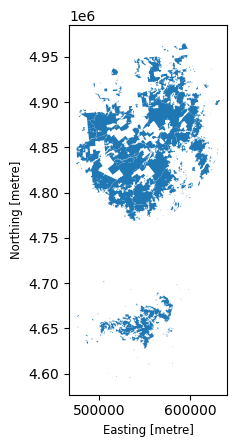

In [14]:
wild_lands.plot()

In [18]:
# View the first five entries in the "geometry" column
wild_lands.geometry.head()

,geometry
0,"POLYGON ((486093.245 4635308.586, 486787.235 4..."
1,"POLYGON ((491931.514 4637416.256, 491305.424 4..."
2,"POLYGON ((486000.287 4635834.453, 485007.55 46..."
3,"POLYGON ((541716.775 4675243.268, 541217.58 46..."
4,"POLYGON ((583896.043 4909643.187, 583891.2 490..."


In [20]:
# Campsites in New York state (Point)
POI_path = os.path.join(path, "DEC_pointsinterest", "DEC_pointsinterest", "Decptsofinterest.shp")
POI_data = gpd.read_file(POI_path)
campsites = POI_data.loc[POI_data.ASSET=='PRIMITIVE CAMPSITE'].copy()

# Foot trails in New York state (LineString)
roads_trails_path = os.path.join(path, "DEC_roadstrails", "DEC_roadstrails", "Decroadstrails.shp")
roads_trails = gpd.read_file(roads_trails_path)
trails = roads_trails.loc[roads_trails.ASSET=='FOOT TRAIL'].copy()

# County boundaries in New York state (Polygon)
counties_path = os.path.join(path, "NY_county_boundaries", "NY_county_boundaries", "NY_county_boundaries.shp")
counties = gpd.read_file(counties_path)

/usr/local/lib/python3.13/dist-packages/geopandas/io/file.py:582: UserWarning: Error parsing datetimes, original strings are returned: Out of bounds nanosecond timestamp: 0216-03-01, at position 347. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)
/usr/local/lib/python3.13/dist-packages/geopandas/io/file.py:582: UserWarning: Error parsing datetimes, original strings are returned: Out of bounds nanosecond timestamp: 1017-02-10, at position 632. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

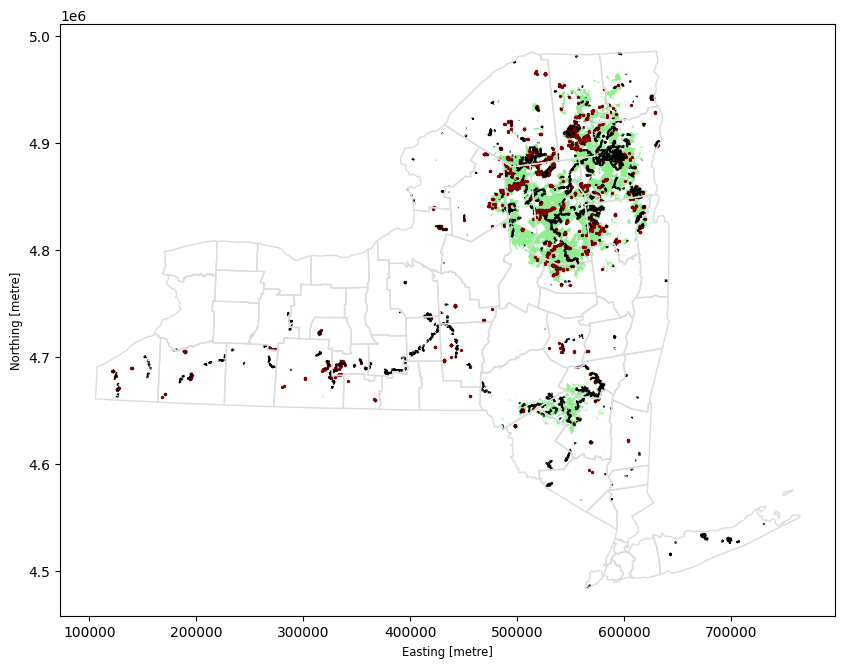

In [21]:
# Define a base map with county boundaries
ax = counties.plot(figsize=(10,10), color='none', edgecolor='gainsboro', zorder=3)

# Add wild lands, campsites, and foot trails to the base map
wild_lands.plot(color='lightgreen', ax=ax)
campsites.plot(color='maroon', markersize=2, ax=ax)
trails.plot(color='black', markersize=1, ax=ax)